## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")

00: Importing torch...done; this took 0.0031ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.29s.
/done


In [2]:
sampler.features

{'ask_vol',
 'bid_vol',
 'df',
 'fit_vol',
 'fwd',
 'is_am',
 'is_american',
 'is_valid',
 'log_open_interest',
 'log_volume',
 'mask_arb_free',
 'nms',
 'pure_ask_price',
 'pure_bid_price',
 'pure_fit_delta',
 'pure_fit_dk',
 'pure_fit_gamma',
 'pure_fit_price',
 'pure_fit_theta',
 'pure_fit_vega',
 'pure_strike',
 'spot_ref',
 'spot_ret',
 'tte_y'}

## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_actatt-big 1.3 [b2aec765|fa6007dd3ce42e6d] created.
00: Trainer for 'AEC train_vol_vol_actatt-big 1.3 [b2aec765|fa6007dd3ce42e6d]'
00: ==========================================================================
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_actatt-big ff89080a/.
00: Launching 'AEC train_vol_vol_actatt-big 1.3 [b2aec765|fa6007dd3ce42e6d]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 128 for valuation.
01:   This model has 2314113 parameters.
01:   Starting afresh.
00: Training 'train_vol_vol_actatt-big' epoch 1/1000 error avg trn 611.7; val 50.58/70.29 [1:57 0.95s 0.24s]. LR: 1.00e-03, GN 10.42, excess_weighted: 0.004325/0.003414, excess_weighted_avg: 0.005958/0.003539, excess_spread: 52.76/70.77, excess

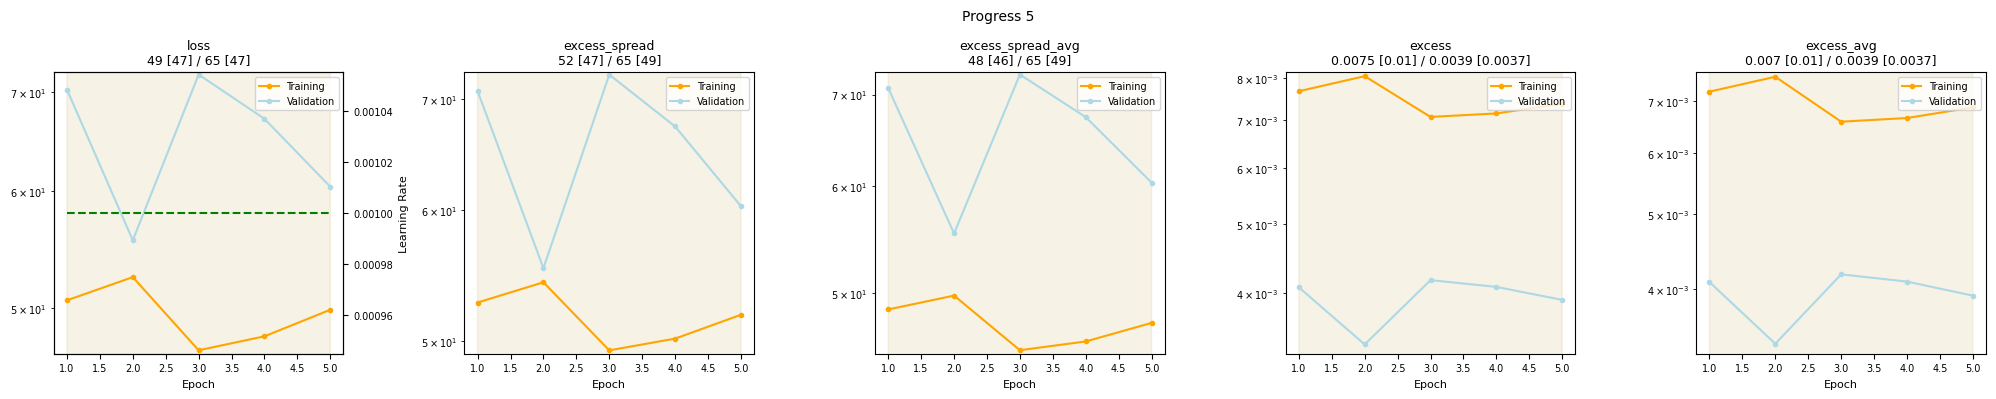

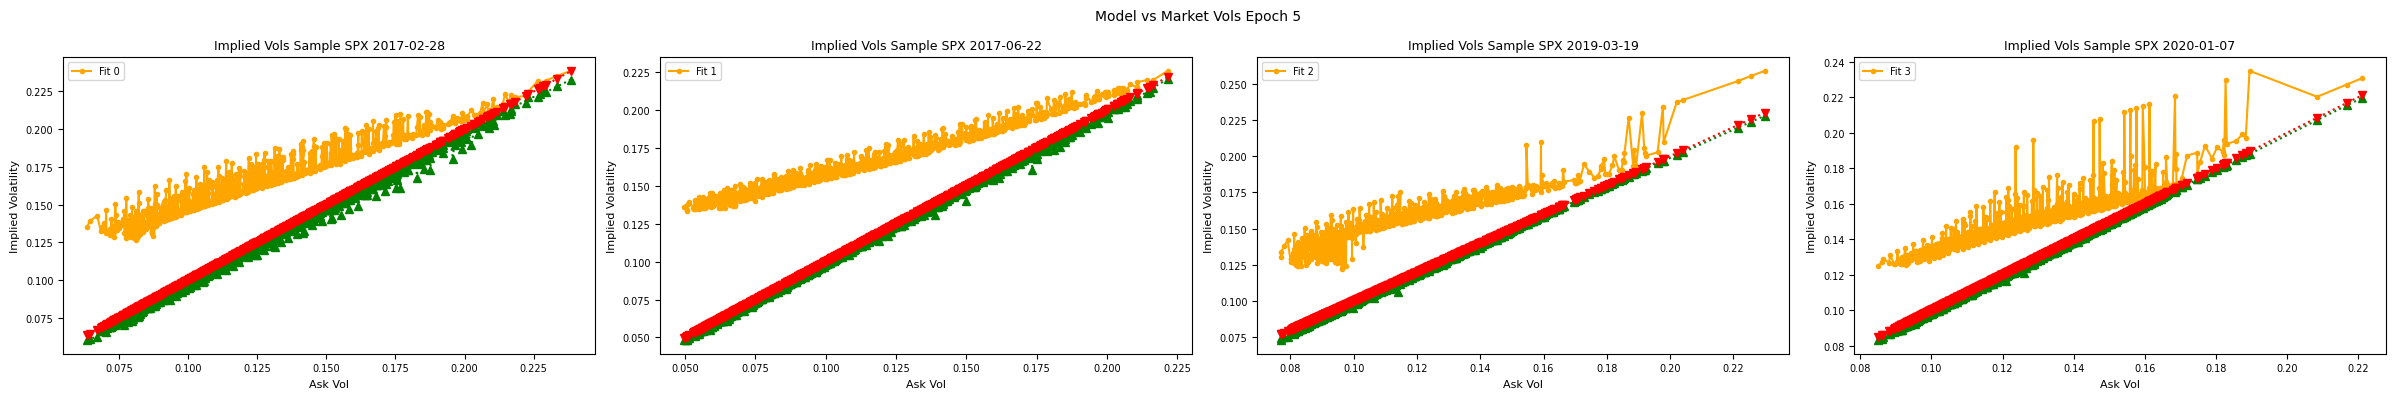

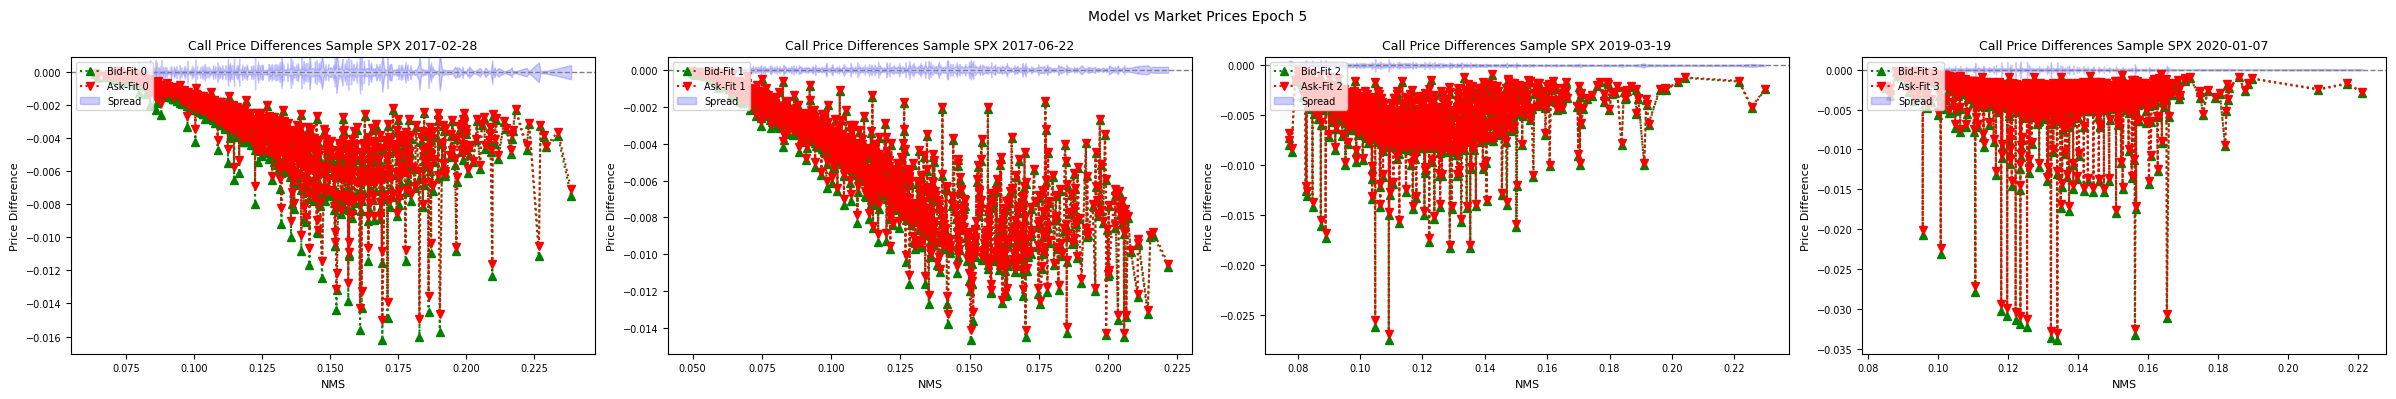

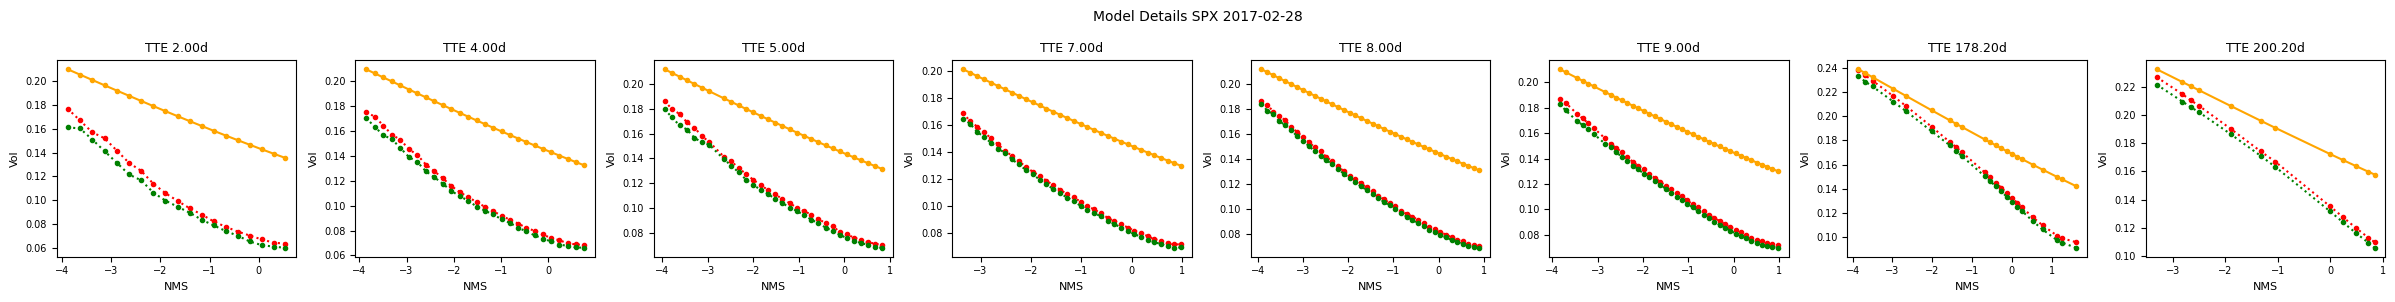

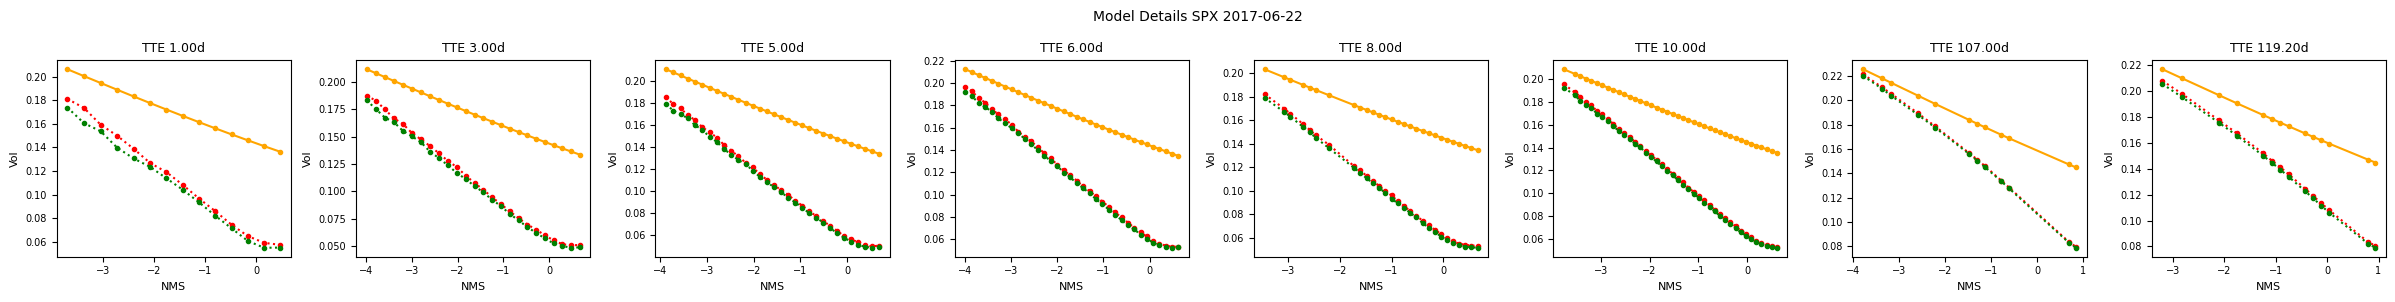

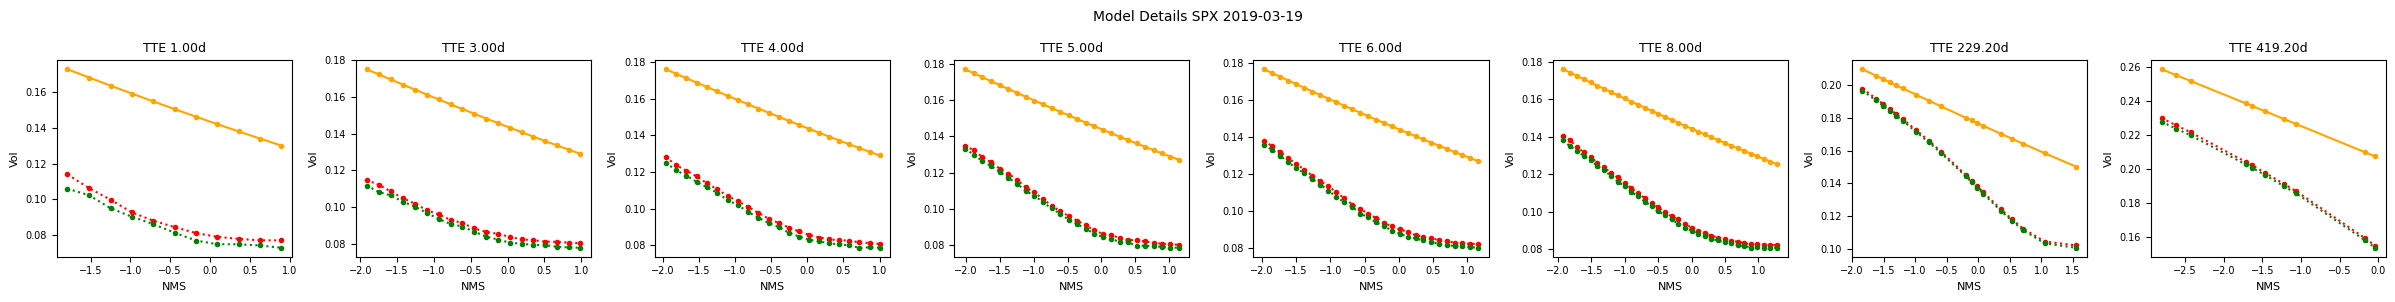

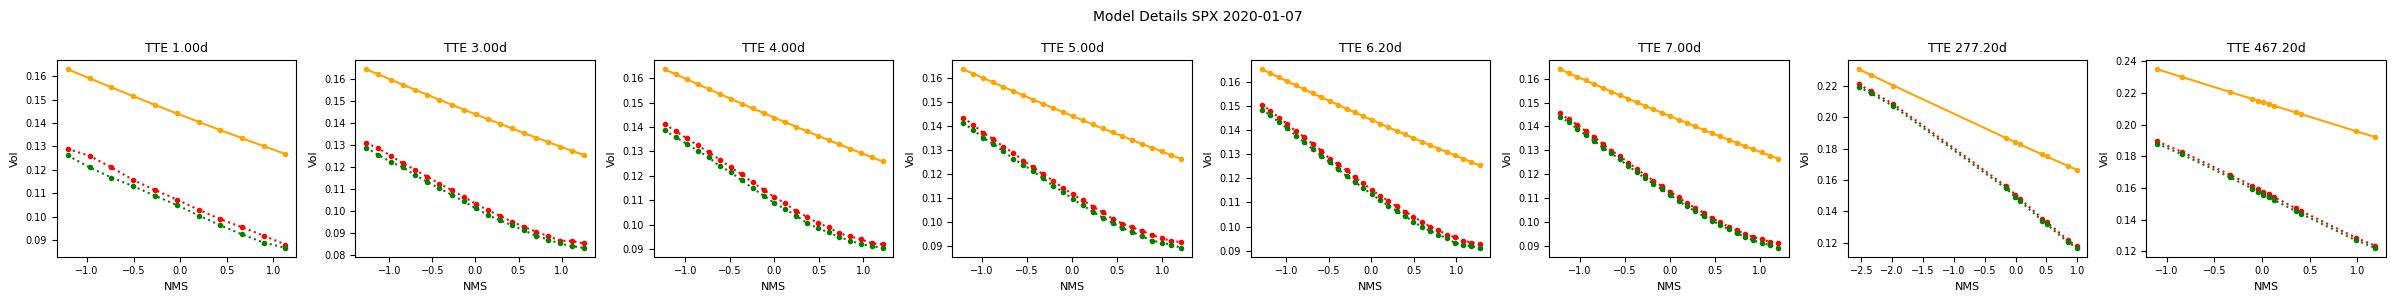

00: Training 'train_vol_vol_actatt-big' epoch 2/1000 error avg trn 53.88; val 52.45/55.55 [3:54 0.95s 0.24s]. LR: 1.00e-03, GN 23.28, excess_weighted: 0.004448/0.00267, excess_weighted_avg: 0.006203/0.00294, excess_spread: 54.26/55.34, excess_spread_avg: 49.82/55.34, excess: 0.008057/0.003393, excess_avg: 0.007533/0.003393. ETA: 66:26:05.
01:   Epoch 2: Saving new best validation loss 55.55 vs. 70.29 at epoch 1 to '/media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_actatt-big ff89080a/best.pt'... done; this took 0.049s.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/fa6007dd3ce42e6d/v1/train_vol_vol_actatt-big ff89080a/last.pt... done; this took 0.033s.
00: Training 'train_vol_vol_actatt-big' epoch 3/1000 error avg trn 48.81; val 46.78/71.96 [5:51 0.95s 0.24s]. LR: 1.00e-03, GN 81.48, excess_weighted: 0.004047/0.003493, excess_weighted_avg: 0.005627/0.003573, excess_spread: 49.37/72.41, excess_spread_avg: 45.42/72.41, e

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    encoder = LatentAttentionEncoderFactory(
        num_head = 64,
        num_QK = 16,
        num_latent = 16,
        KV_config = FeedForward.Config(
            num_depth = 1,
            num_width = 64, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 128, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 3,
            num_width = 128,
            activation = 'Softplus',    
        )
    )
)

with torch.compiler.set_stance("force_eager"):
    run( ipynbname.name(), version="1.3", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, debug=False, val_batch_size=128 )


In [ ]:

@dataclass(frozen=True)
class A:
    a = 1

    def f(self):
        self.__dict__['c'] = 1
a = A()
a.f()
a.c